In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Datos

Taza de muertes por estado

In [6]:
state = pd.DataFrame({
    "state": ["Alabama", "Alaska", "Arizona", "Arkansas", "California", "Colorado", "Connecticut", "Delaware"],
    "population": [4779736, 710231, 6392017, 2915918, 37253956, 5029196,3574097,897934],
    "murder_rate": [5.7, 5.6, 4.7, 5.6,4.4,2.8,2.4,5.8],
    "abbreviation": ["AL", "AK", "AZ", "AR", "CA", "CO", "CT", "DE"]
})

state.head()

,state,population,murder_rate,abbreviation
0,Alabama,4779736,5.7,AL
1,Alaska,710231,5.6,AK
2,Arizona,6392017,4.7,AZ
3,Arkansas,2915918,5.6,AR
4,California,37253956,4.4,CA


In [7]:
state["population"].std()

np.float64(12105745.29585633)

In [8]:
state["population"].quantile(0.75) - state["population"].quantile(0.25)

np.float64(2958479.25)

# Boxplot

Boxplot o también conocido como box and whiskers plot,  permite hacer una visualización rápida basada en percentiles permite dar una vista rápida de la distribución de los datos. En el caso de `R` , ya provee una funcón boxplot que despliega el grafico sin mucho problemas. Pandas provee un numero de funciones de exploracion para diagramas, una de esas es el boxplot

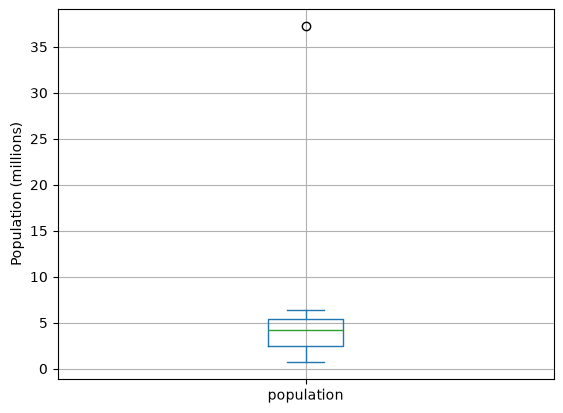

In [9]:
ax = (state["population"] / 1_000_000).plot.box()

ax.set_ylabel("Population (millions)")
ax.grid(True)

el boxplot permite de forma visual ver rapidamente la distribucion de los datos, la raya horizontal que esta dentro de la caja representa donde esta la mediana mientras que la caja en si misma representa donde esta el 50% de los datos, los puntos que estan antes o despues de las lineas verticales se consideran valores atipicos ,extremos o outliers:

- **La caja (Rango Intercuartílico o IQR):** Abarca el 50% central de los datos. El borde inferior es el primer cuartil ($Q_1$ o percentil 25) y el borde superior es el tercer cuartil ($Q_3$ o percentil 75).
- **La línea dentro de la caja:** Marca la mediana ($Q_2$ o percentil 50), dividiendo la distribución a la mitad. En tu gráfico, la línea verde muestra que la mediana de población ronda los 4 a 5 millones.
- **Los bigotes (whiskers):** Las líneas verticales que salen de la caja se extienden habitualmente hasta el valor más lejano que no supere $1.5 \times \text{IQR}$ desde los bordes de la caja. Delimitan el rango de valores considerados estadísticamente "normales" para esta distribución.
- **Puntos fuera de los bigotes (outliers):** Cualquier observación que quede más allá de las marcas horizontales de los bigotes se grafica de forma individual como un valor atípico o extremo. En el gráfico se aprecia un caso claro alrededor de los 37 millones de habitantes.

# Cuartiles

Los cuartiles ($Q_k$) indica la división en 3 subconjuntos de igual longitud basado en encontrar la mediana de cada subconjunto, para poder hacer el procedimiento, el conjunto debe estar ordenado y a partir de ahí procedemos a buscar el elemento central, en python podemos usar un array y encontrar el valor del centro de forma recursiva

## Implementación manual

In [17]:
import numpy as np

def get_quartiles(elements,  k: int):

    n = len(elements)
    
    if k is None or k <= 0:
        raise ValueError(f"{q} is not a valid quartile")

    return ((n + 1) * k) / 4
    

def get_exact_position(elements, k: int):
    pos = get_quartiles(elements, k)
    dec = pos%1
    int_pos = int(pos)
    if dec > 0:
        return int((elements[int_pos] + elements[int_pos + 1]) / 2) - 1

    return int_pos - 1
    



# Este array debe estar ordenado para hacer este procedimiento
elements = np.array([10, 15, 16, 17, 18, 20, 32])
k = 3

print("Número de elementos: ", len(elements))
print("Posición del cuartil k: ", get_exact_position(elements, k))
print(elements[get_exact_position(elements, k)])
print("IQR: ", elements[get_exact_position(elements, 3)] - elements[get_exact_position(elements, 1)])
print("Mediana segun numpy: ", np.median(elements))

Número de elementos:  7
Posición del cuartil k:  5
20
IQR:  5
Mediana segun numpy:  17.0


In [36]:
isinstance(1.0, int)

False

# Tabla de frecuencia

Se usa para poder observar cual es la frecuencia de estados (en este caso) que hay en diferentes intervalos. `bins` hace referencia al ancho del intervalo en cuestión, a continuación el método `pd.cut` divide el campo population en 10 intervalos y muestra lo que hay entre cada uno de los intervalos

In [23]:
cuts = pd.cut(state["population"], 10)

cuts.value_counts().sort_index()

population
(673687.275, 4364603.5]     4
(4364603.5, 8018976.0]      3
(8018976.0, 11673348.5]     0
(11673348.5, 15327721.0]    0
(15327721.0, 18982093.5]    0
(18982093.5, 22636466.0]    0
(22636466.0, 26290838.5]    0
(26290838.5, 29945211.0]    0
(29945211.0, 33599583.5]    0
(33599583.5, 37253956.0]    1
Name: count, dtype: int64

## Histograma

Un histograma es una forma facil de visualizar una tabla de frecuencias. ```pandas``` puede generar histogramas usando el metodo hist y controlarlo mediante los parametros


Text(0.5, 0, 'Population (millions)')

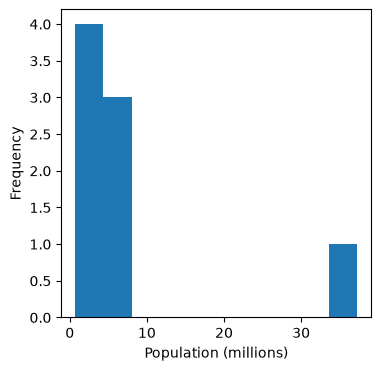

In [22]:
ax = (state["population"] / 1_000_000).plot.hist(figsize=(4,4))

ax.set_xlabel("Population (millions)")

## Densidad


La densidad se representa como una linea suave que muestra la distribución de los valores como una linea continua, un plot de densidad puede ser pensado como un histograma suavizado

Text(0.5, 0, 'Murder rate (per 100000)')

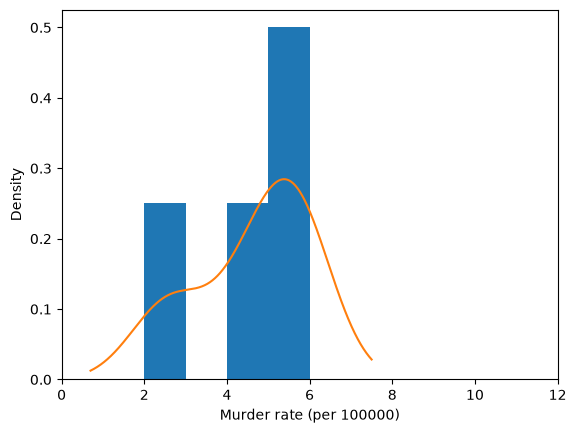

In [25]:
ax = state["murder_rate"].plot.hist(density=True, xlim=[0,12], bins=range(1,12))
state["murder_rate"].plot.density(ax=ax)

ax.set_xlabel("Murder rate (per 100000)")

# Categoricas

El grafico de barras ayuda a ver la frecuencia en la que una variable categorica ocurre en el dataset

In [32]:
df = pd.DataFrame({
    "Carrier": [23.02],
    "ATC": [30.40],
    "Weather": [4.03],
    "Security": [0.12],
    "Inbound": [42.43]
})

df.head()

,Carrier,ATC,Weather,Security,Inbound
0,23.02,30.4,4.03,0.12,42.43


Text(0, 0.5, 'Count')

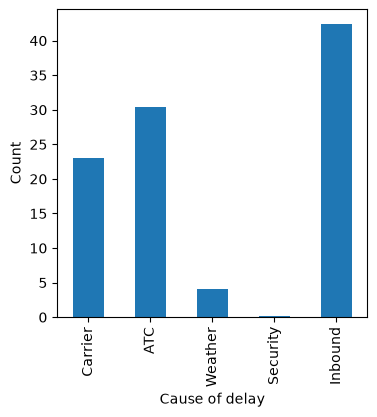

In [33]:
ax = df.transpose().plot.bar(figsize=(4,4), legend=False)
ax.set_xlabel("Cause of delay")
ax.set_ylabel("Count")